In [1]:
from _Aplha_n_methods import Alpha_N_calc as an
from _Geometry_methods import Geometry_helper as gh
from _Prettyplt import PrettyPlot as pp

import openmc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import os
pp.makePretty(0.7)

In [2]:
#Setting geometry and materials
#Geometry
new_geom = True
date = "011026"
hour = 0

fuel_name = 'Fuel_CA_2'
blanket_name = 'Blanket_CA'


#Reactor geometry parameters
inner_fuel_r = 50
outer_fuel_r = 60
outer_moderater_r = 80
blanket_or = 100
    
#Control for readtor
inner_moderator_height = 80
    
materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
#materials = gh.create_materials(fuel_name)
geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                        with_blanket=True, blanket_or=blanket_or, 
                                        inner_moderator_height=inner_moderator_height, 
                                        materials=materials, fuel_name=fuel_name)



fuel = gh.get_material_by_name(fuel_name,materials)
blanket = gh.get_material_by_name(blanket_name,materials)

fuel.set_density('g/cm3',4.905)
blanket.set_density('g/cm3',4.626)

Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2


In [3]:
#Print materials
def print_dep_material(material,threshold = 1e-9):
    total = 0
    new_total = 0
    print(f'\n{material.name}')
    print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        new_total += nuc_percent
        if nuc_percent > threshold:
            print(f'{nuc_name}\t {nuc_percent:.3g}')
    print(f'total: {total:.5g}')
    print(f'new_total: {new_total:.5g}')
def check_fuel_from_ORNL(fuel,threshold = 1e-7):
    print('\n',fuel.name)
    nuclide_lib = {}
    total = 0
    for nuc,dens in fuel.get_nuclide_densities().items():
        symbol,Z,A = an.isolate_atomic_symbol(nuc)
        if symbol != 'F':
            #print(nuc,dens)
            mol = dens.percent
            total += mol
            if symbol in nuclide_lib:
                nuclide_lib[symbol]+=mol
            else:
                nuclide_lib[symbol]=mol
    
    for nuc in nuclide_lib:
        if nuclide_lib[nuc]/total*100 > threshold and nuc != 'F':
            print(f'{nuc}: {nuclide_lib[nuc]/total*100:.10g}')

print_dep_material(fuel)
print_dep_material(blanket)

check_fuel_from_ORNL(fuel)
check_fuel_from_ORNL(blanket)



Fuel_CA_2
density: 4.905
F19	 0.644
Li6	 2.6e-06
Li7	 0.26
U234	 4.3e-05
U235	 0.00481
U236	 2.21e-05
U238	 0.0912
total: 0.08001
new_total: 1

Blanket_CA
density: 4.626
F19	 0.655
Li6	 1.79e-05
Li7	 0.241
Th230	 2.07e-05
Th232	 0.103
total: 0.073034
new_total: 1

 Fuel_CA_2
Li: 72.99999995
Mo: 1.452025466e-07
Np: 1.966203655e-07
U: 26.99999897
Zr: 1.219411669e-07

 Blanket_CA
Li: 70
Th: 29.99999994




 Fuel_CA_2
Writing SRIM file after 47 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71


/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=1.
  warn(msg, IDWarning)


Getting cross sections...
Making kernels and integrent...
setup done in 18.037212758998066 s
total_n_per_s: 3.535e+05 for Fuel_CA_2


 Blanket_CA
Writing SRIM file after 37 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71
Getting cross sections...
Making kernels and integrent...
setup done in 20.682909277998988 s
total_n_per_s: 4.0498e+05 for Blanket_CA


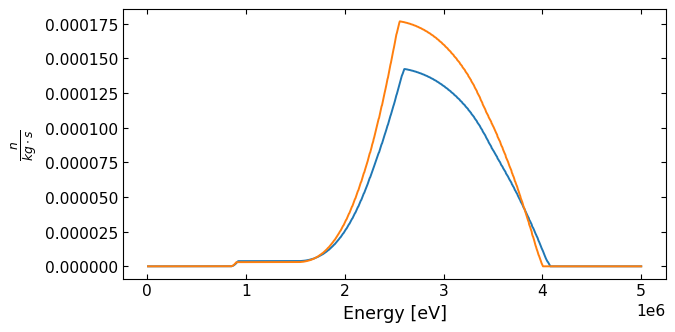

In [4]:
#Alpha-n from material
def shell_vol_calc(geom_or,geom_ir):
    volume=4/3*np.pi*(geom_or**3-geom_ir**3)
    return volume

def set_source(material,innr_r,outer_r):
    print(f'\n\n {material.name}')
    n_intensities,n_energies,n_per_s_per_kg = an.neutron_spectra_from_material(material,E_min=1e4,
                                                                               nr_points=1000,nr_energies=1000,
                                                                               new_file=True)
    
    n_intensities = np.clip(n_intensities,0,None)
    energy = openmc.stats.Tabular(n_energies, n_intensities)
    
    ax.plot(n_energies,n_intensities,label=material.name)
    
    material_vol = shell_vol_calc(outer_fuel_r,inner_fuel_r)
    material_mass = material.density*material_vol/1000
    total_n_per_s = n_per_s_per_kg*material_mass

    print(f'total_n_per_s: {total_n_per_s:.5g} for {material.name}')

    return openmc.IndependentSource(space=fuel_space, energy=energy,particle='neutron', strength=total_n_per_s)

inner_fuel_radius = geom.get_surfaces_by_name('fuel_inner')[0].bounding_box('-')[1][0]
outer_fuel_radius = geom.get_surfaces_by_name('fuel_outer')[0].bounding_box('-')[1][0]

inner_blanket_radius = geom.get_surfaces_by_name('blanket_inner')[0].bounding_box('-')[1][0]
outer_blanket_radius = geom.get_surfaces_by_name('blanket_outer')[0].bounding_box('-')[1][0]

fuel_space = openmc.stats.spherical_uniform(r_outer=outer_fuel_radius,r_inner=inner_fuel_radius)
blanket_space = openmc.stats.spherical_uniform(r_outer=outer_blanket_radius,r_inner=inner_blanket_radius)

fig,ax =plt.subplots()

ax.set_xlabel('Energy [eV]')
ax.set_ylabel(r'$\frac{n}{kg\cdot s}$')

fuel_src = set_source(fuel,inner_fuel_radius,outer_fuel_radius)
blanket_src = set_source(blanket,inner_blanket_radius,outer_blanket_radius)








In [5]:
#Settings
settings = openmc.Settings()
settings.run_mode = 'eigenvalue'
settings.source =  [fuel_src,blanket_src]   # evt. + SF-kilde som separat source
settings.batches = 50
settings.inactive = 10
settings.particles = 10000 # is changed later

#Fixing Li6 at 900 K doesn't have a cross section 
settings.temperature = {
    'method': 'nearest',
    'tolerance': 1000}

model_eigen = openmc.Model(geometry=geom, materials=materials, settings=settings)



In [6]:
#Finding k_eff
model_eigen.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

PosixPath('/root/Speciale/statepoint.50.h5')